# Cohete_balances

Modelo de tres fases


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid

## 1. Datos de entrada


In [2]:
# Geometría y masa
Vb = 0.0015          # volumen de botella [m3]
Vw0 = 0.0005         # volumen inicial de agua [m3]
ms = 0.054          # masa seca TOTAL del cohete [kg]
D = 0.075           # diámetro exterior del cuerpo [m]
Dg = 0.024          # diámetro interior de garganta [m]
Lref = 0.45        # largo de referencia [m]

# Condiciones iniciales y ambiente
p0_man = 92000.0      # presión inicial MANOMÉTRICA [Pa] (supuesto propio según primeros lanzamientos)
pamb = 101300.0        # presión atmosférica absoluta [Pa]
Tg0 = 298.15         # temperatura inicial del gas [K]
Tw0 = 298.15         # temperatura inicial de pared [K]
Tinf = 298.15        # temperatura exterior [K]
theta0 = 90.0      # ángulo respecto a la horizontal [grados]
Uinf = 0.0        # velocidad horizontal del viento [m/s] (supuesto fuerte)
g = 9.81           # gravedad [m/s2]

# Coeficientes y propiedades de los fluidos
Cd = 0.9          # coeficiente de descarga [adimensional]
CD = 0.325          # coeficiente de arrastre [adimensional]
rho_w = 1000.0       # densidad del agua [kg/m3]
rho_inf = 1.226     # densidad del aire exterior [kg/m3]
R = 287.0           # constante particular del aire [J/(kg K)]
cv = 717.0          # calor específico del aire a volumen constante [J/(kg K)]
cp = 1006.0          # calor específico del aire a presión constante [J/(kg K)]
gamma = 1.403       # cp/cv [adimensional]
mu_w = 0.001139        # viscosidad dinámica del agua [Pa s]
mu_aire = 1.793e-05     # viscosidad dinámica del aire [Pa s]
nu_aire = 1.47e-05     # viscosidad cinemática del aire exterior [m2/s]
k_aire = 0.02525      # conductividad térmica del aire [W/(m K)]
Pr = 0.714          # número de Prandtl [adimensional]

# Acoplamiento térmico de gas y pared
hi = 4.84         # convección interna [W/(m2 K)]
m_est = 0.052       # masa estructural del nodo térmico [kg]
c_est = 1250.0       # calor específico de la estructura [J/(kg K)]
m_rec = 0.002       # recubrimiento base incluido en la masa seca [kg]
c_rec = 1250.0      # capacidad específica estimada del recubrimiento base [J/(kg K)]
cp_w = 4180.0        # calor específico del agua [J/(kg K)]
ePET = 0.00025        # espesor de PET [m]
rhoPET = 1350.0      # densidad del PET [kg/m3] (solo para 1D)
cpPET = 1250.0       # calor específico PET [J/(kg K)] (solo para 1D)
kPET = 0.3        # conductividad del PET [W/(m K)]

# Radiación y sol
epsilon = 0.90      # emisividad de la superficie exterior (estimada; no medida)
sigma = 5.67e-08       # constante de Stefan Boltzmann [W/(m2 K4)]
alpha_s = 0.0     # absortividad solar [adimensional]
G = 0.0           # irradiancia solar [W/m2] (0 si corresponde)
Ap = 0.03          # área proyectada para radiación solar [m2]

# Integración numérica
max_paso = 0.002      # paso máximo del integrador [s]
paso_salida = 0.005   # separación entre datos exportados [s]
error_rel = 1e-8      # tolerancia relativa del integrador
error_abs = 1e-10     # tolerancia absoluta del integrador
fin_relativo = 1e-3   # corte de la fase de aire: p/pamb = 1 + fin_relativo
t_max = 25.0          # tiempo máximo de cálculo [s]

# Capa adicional de espuma rígida de poliuretano (PUR), solo en T3.5
e_ais = 0.0
k_ais = 0.040           # W/(m K), valor conservador de MUSAAT
rho_ais = 50.0          # kg/m3, valor representativo
cp_ais = 1250.0         # J/(kg K), aproximación para el modelo
h_ensayo = 145.0         # h externo de referencia del equipo [W/(m2 K)]


In [3]:
# Comprobación de los datos y cálculos geométricos
nombres = ["Vb", "Vw0", "ms", "D", "Dg", "Lref", "p0_man", "pamb", "Tg0", "Tw0", "Tinf", "theta0", "Uinf", "g", "Cd", "CD", "rho_w", "rho_inf", "R", "cv", "cp", "gamma", "mu_w", "mu_aire", "nu_aire", "k_aire", "Pr", "hi", "m_est", "c_est", "m_rec", "c_rec", "cp_w", "ePET", "kPET", "epsilon", "sigma", "alpha_s", "G", "Ap"]
faltan = [nombre for nombre in nombres if globals()[nombre] is None]
if faltan:
    raise ValueError("Completar los parámetros en la celda anterior: " + ", ".join(faltan))

if not (Vb > Vw0 > 0 and ms > 0 and p0_man > 0 and pamb > 0 and D > 0 and Dg > 0):
    raise ValueError("Revisar volumen, masa, presión y diámetros.")
if not (0 < Cd <= 1 and CD >= 0 and hi >= 0 and m_est > 0 and m_rec >= 0):
    raise ValueError("Revisar Cd, CD y parámetros térmicos.")
if not (R > 0 and cv > 0 and cp > cv and gamma > 1 and rho_w > 0 and rho_inf > 0):
    raise ValueError("Revisar las propiedades de los fluidos.")
if not (0 <= theta0 <= 90 and 0 < paso_salida <= t_max):
    raise ValueError("Revisar theta0 o paso_salida.")

Ag = np.pi * Dg**2 / 4
Af = np.pi * D**2 / 4
Ai = np.pi * D * Lref       # aproximación de cilindro para la cara interior
Alat = np.pi * D * Lref     # aproximación de cilindro para la cara exterior
Va0 = Vb - Vw0
p0 = p0_man + pamb
mg0 = p0 * Va0 / (R * Tg0)
m0 = ms + rho_w * Vw0 + mg0
Tcielo = 0.0552 * Tinf**1.5

print("Área de garganta:   ", Ag, "m2")
print("Área frontal:       ", Af, "m2")
print("Volumen inicial aire:", Va0, "m3")
print("Masa de aire inicial:", mg0, "kg")
print("Masa total inicial: ", m0, "kg")

Área de garganta:    0.0004523893421169302 m2
Área frontal:        0.004417864669110647 m2
Volumen inicial aire: 0.001 m3
Masa de aire inicial: 0.0023293071546362314 kg
Masa total inicial:  0.5563293071546362 kg


## 2. Ecuaciones acopladas

**Fase I:** el gas conserva su masa; varía el volumen de aire y se expulsa agua. 

**Fase II:** el volumen permanece constante y disminuye la masa de gas. 

**Fase III:** se anula el empuje y la masa es constante.

Las ecuaciones de presión, temperatura, empuje y movimiento se calculan en el mismo paso temporal. La convección exterior varía con el número de Reynolds. La pared se modela con capacidad térmica concentrada

In [4]:
def calculos(t, estado, fase):
    # Estado: posición, velocidad, volumen aire, masa gas, temperatura gas, temperatura pared
    x, y, vx, vy, Va, mg, Tg, Tw = estado
    Va = max(Va, 1e-12)
    mg = max(mg, 1e-12)
    Tg = max(Tg, 1.0)
    Vrel = np.sqrt((vx-Uinf)**2 + vy**2)

    # Convección externa: Re, Nu y h exterior
    ReL = Vrel * Lref / nu_aire
    if ReL < 5e5:
        NuL = 0.664 * np.sqrt(ReL) * Pr**(1/3)
    else:
        NuL = (0.037 * ReL**0.8 - 871) * Pr**(1/3)
    hext = max(0.0, NuL * k_aire / Lref)

    h_ef = hext/(1 + hext*(ePET/kPET + e_ais/k_ais))
    Qext = h_ef * Alat * (Tinf-Tw)
    Qrad = epsilon * sigma * Alat * (Tcielo**4 - Tw**4)
    Qsolar = alpha_s * G * Ap

    # Magnitudes dependientes de la fase
    p = mg * R * Tg / Va
    dVa = 0.0
    dmg = 0.0
    dTg = 0.0
    F = 0.0
    ve = 0.0
    mdot_w = 0.0
    mdot_e = 0.0
    pe = pamb

    if fase == 1:
        p = mg * R * Tg / Va
        delta_p = max(p - pamb, 0.0)
        ve = np.sqrt(2 * delta_p / rho_w)
        dVa = Cd * Ag * ve
        mdot_w = rho_w * dVa
        F = mdot_w * ve
        m_agua = rho_w * max(Vb-Va, 0)
        m = ms + m_agua + mg
        Qi = hi * Ai * (Tw-Tg)
        dTg = (-p*dVa + Qi) / (mg*cv)

    elif fase == 2:
        Va = Vb
        p = mg * R * Tg / Vb
        rayon = p / pamb
        rayon_critica = ((gamma+1)/2)**(gamma/(gamma-1))
        if rayon > 1:
            if rayon >= rayon_critica:
                mdot_e = (Cd*Ag*p/np.sqrt(Tg) * np.sqrt(gamma/R)
                          * (2/(gamma+1))**((gamma+1)/(2*(gamma-1))))
                pe = p*(2/(gamma+1))**(gamma/(gamma-1))
                Te = Tg * 2/(gamma+1)
                ve = np.sqrt(gamma * R * Te)
            else:
                r = pamb/p
                mdot_e = Cd*Ag*p*np.sqrt(2*gamma/((gamma-1)*R*Tg)) * np.sqrt(
                    max(r**(2/gamma)-r**((gamma+1)/gamma), 0.0))
                pe = pamb
                ve = np.sqrt(max(2*gamma*R*Tg/(gamma-1)
                         * (1-r**((gamma-1)/gamma)), 0.0))
        dmg = -mdot_e
        F = mdot_e*ve + (pe-pamb)*Ag
        m_agua = 0.0
        m = ms + mg
        Qi = hi*Ai*(Tw-Tg)
        dTg = (-mdot_e*R*Tg + Qi)/(mg*cv)

    else:
        # Vuelo libre: no queda empuje, la masa se mantiene fija, presion interna iguala a presión atmosferica externa
        m_agua = rho_w * max(Vb-Va, 0.0)
        m = ms + m_agua + mg
        Qi = 0.0

    # Energía de la pared: incluye la masa de agua que aún se encuentra dentro
    Cw = m_est*c_est + m_rec*c_rec + m_agua*cp_w
    dTw = (-Qi + Qext + Qrad + Qsolar)/Cw

    # Cantidad de movimiento en x e y
    ex = np.cos(np.radians(theta0))
    ey = np.sin(np.radians(theta0))
    FDx = -0.5*rho_inf*CD*Af*Vrel*(vx-Uinf)
    FDy = -0.5*rho_inf*CD*Af*Vrel*vy
    ax = (F*ex + FDx)/m
    ay = (F*ey + FDy)/m - g

    return (ax, ay, dVa, dmg, dTg, dTw, F, p, m, ve,
            mdot_w, mdot_e, FDx, FDy, ReL, NuL, hext,
            Qi, Qext, Qrad, Qsolar, Cw)


def ecuaciones(t, estado, fase):
    x, y, vx, vy, Va, mg, Tg, Tw = estado
    ax, ay, dVa, dmg, dTg, dTw, *_ = calculos(t, estado, fase)
    return [vx, vy, ax, ay, dVa, dmg, dTg, dTw]

## 3. Integración de las tres fases


In [5]:
def evento_agua(t, estado):
    return Vb - estado[4]
evento_agua.terminal = True
evento_agua.direction = -1


def evento_presion_agua(t, estado):
    return estado[5]*R*estado[6]/max(estado[4], 1e-12)-pamb
evento_presion_agua.terminal = True
evento_presion_agua.direction = -1


def evento_fin_aire(t, estado):
    return estado[5]*R*estado[6]/Vb - pamb*(1+fin_relativo)
evento_fin_aire.terminal = True
evento_fin_aire.direction = -1


def evento_suelo(t, estado):
    return estado[1]
evento_suelo.terminal = True
evento_suelo.direction = -1


def simular(paso_maximo=max_paso, tolerancia=error_rel):
    estado0 = np.array([0., 0., 0., 0., Va0, mg0, Tg0, Tw0])
    partes = []

    solucion1 = solve_ivp(lambda t,estado: ecuaciones(t,estado,1), [0,t_max], estado0,
                          method='RK45', events=[evento_agua, evento_presion_agua],
                          dense_output=True, max_step=paso_maximo,
                          rtol=tolerancia, atol=error_abs)
    if not solucion1.success:
        raise RuntimeError(solucion1.message)
    partes.append((1, solucion1))
    estado1 = solucion1.y[:, -1].copy()
    t1 = solucion1.t[-1]
    # En el caso habitual, la primera fase termina por agotamiento de agua
    agua_agotada = len(solucion1.t_events[0]) > 0

    if agua_agotada:
        estado1[4] = Vb
        solucion2 = solve_ivp(lambda t,estado: ecuaciones(t,estado,2), [t1,t_max], estado1,
                              method='RK45', events=evento_fin_aire,
                              dense_output=True, max_step=paso_maximo,
                              rtol=tolerancia, atol=error_abs)
        if not solucion2.success:
            raise RuntimeError(solucion2.message)
        partes.append((2, solucion2))
        estado2 = solucion2.y[:, -1].copy()
        t2 = solucion2.t[-1]
    else:
        estado2 = estado1
        t2 = t1

    solucion3 = solve_ivp(lambda t,estado: ecuaciones(t,estado,3), [t2,t_max], estado2,
                          method='RK45', events=evento_suelo,
                          dense_output=True, max_step=paso_maximo,
                          rtol=tolerancia, atol=error_abs)
    if not solucion3.success:
        raise RuntimeError(solucion3.message)
    partes.append((3, solucion3))

    # Crear tabla con tiempos y variables, sin repetir instantes de transición
    filas = []
    nombres_extra = ['ax','ay','dVa','dmg','dTg','dTw','F','p','m','ve',
                     'mdot_w','mdot_e','FDx','FDy','ReL','NuL','hext',
                     'Qi','Qext','Qrad','Qsolar','Cw']
    for fase, sol in partes:
        tiempos = np.arange(sol.t[0], sol.t[-1], paso_salida)
        tiempos = np.append(tiempos, sol.t[-1])
        for t in tiempos:
            estado = sol.sol(t)
            extra = calculos(t, estado, fase)
            fila = dict(zip(['x','y','vx','vy','Va','mg','Tg','Tw'], estado))
            fila.update(dict(zip(nombres_extra, extra)))
            fila['t'] = t
            fila['fase'] = fase
            filas.append(fila)
    tabla = pd.DataFrame(filas)
    tabla['Vrel'] = np.sqrt((tabla.vx-Uinf)**2+tabla.vy**2)
    tabla['Re_g'] = np.where(tabla.fase==1,
                            tabla.mdot_w*Dg/(Ag*mu_w),
                            tabla.mdot_e*Dg/(Ag*mu_aire))
    return tabla, partes, t1, t2, agua_agotada

In [6]:
resultados, partes, ta, tb, agua_agotada = simular()

altura_max = resultados.y.max()
alcance = resultados.x.iloc[-1]
vel_max = resultados.Vrel.max()
impulso = 0
for f in [1, 2]:
    datos = resultados[resultados.fase==f]
    if len(datos) >= 2:
        impulso += trapezoid(datos.F, datos.t)

print('Tiempo expulsión de agua:', round(ta, 5), 's')
print('Tiempo fin del empuje:  ', round(tb, 5), 's')
print('Agua expulsada completa:', agua_agotada)
print('Altura máxima:          ', round(altura_max, 3), 'm')
print('Alcance horizontal:     ', round(alcance, 3), 'm')
print('Velocidad relativa máx.:', round(vel_max, 3), 'm/s')
print('Impulso aproximado:    ', round(impulso, 4), 'N s')
print('Duración del vuelo:     ', round(resultados.t.iloc[-1], 3), 's')

Tiempo expulsión de agua: 0.15141 s
Tiempo fin del empuje:   0.15514 s
Agua expulsada completa: True
Altura máxima:           11.432 m
Alcance horizontal:      0.0 m
Velocidad relativa máx.: 15.349 m/s
Impulso aproximado:     4.4935 N s
Duración del vuelo:      3.131 s


## 4. Tablas de resultados y comprobaciones

La tabla incluye las variables de estado, el arrastre en cada eje, el empuje, los caudales y las potencias de transferencia. En la subida `FDy` es negativo, en el descenso `FDy` es positivo

In [7]:
# Primeras filas, última fila y valores máximos
columnas = ['t','fase','x','y','vx','vy','m','p','Tg','Tw','F','ve','mdot_w','mdot_e','FDy','ReL','NuL','hext','Qi','Qext','Qrad','Qsolar']
display(resultados[columnas].head(8).round(5))
display(resultados[columnas].tail(8).round(5))

print('Presión máxima:', resultados.p.max(), 'Pa')
print('Empuje máximo:', resultados.F.max(), 'N')
print('Caudal máximo de agua:', resultados.mdot_w.max(), 'kg/s')
print('Caudal máximo de aire:', resultados.mdot_e.max(), 'kg/s')
print('Reynolds máximo en la garganta:', resultados.Re_g.max())
print('Bi externo máximo (PET):', (resultados.hext*ePET/kPET).max())
print('Bi interno (PET):', hi*ePET/kPET)
print('Mach exterior máximo aproximado:', resultados.Vrel.max()/np.sqrt(gamma*R*Tinf))
print('Calentamiento de recuperación máximo [K]:',
      (Pr**(1/3))*(resultados.Vrel.max()**2)/(2*cp))

,t,fase,x,y,vx,vy,m,p,Tg,Tw,...,mdot_w,mdot_e,FDy,ReL,NuL,hext,Qi,Qext,Qrad,Qsolar
0,0.000,1,0.0,0.00000,0.0,0.00000,0.55633,193300.00000,289.15000,289.15000,...,5.52286,0.0,-0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-8.46255,0.0
1,0.005,1,0.0,0.00154,0.0,0.61400,0.52926,186206.52463,286.07794,289.14998,...,5.30567,0.0,-0.00033,18795.84385,81.36390,4.56542,1.59605,0.00001,-8.46254,0.0
2,0.010,1,0.0,0.00611,0.0,1.20892,0.50325,179802.13204,283.23504,289.14995,...,5.10165,0.0,-0.00129,37007.70752,114.16866,6.40613,3.07304,0.00003,-8.46252,0.0
3,0.015,1,0.0,0.01360,0.0,1.78671,0.47823,173992.72056,280.59634,289.14992,...,4.90925,0.0,-0.00281,54695.07747,138.79536,7.78796,4.44393,0.00007,-8.46251,0.0
4,0.020,1,0.0,0.02395,0.0,2.34907,0.45414,168700.88413,278.14069,289.14988,...,4.72719,0.0,-0.00486,71910.18337,159.14611,8.92986,5.71973,0.00011,-8.46249,0.0
5,0.025,1,0.0,0.03707,0.0,2.89751,0.43094,163862.34561,275.85001,289.14984,...,4.55435,0.0,-0.00739,88699.31203,176.75062,9.91767,6.90980,0.00017,-8.46246,0.0
6,0.030,1,0.0,0.05290,0.0,3.43339,0.40858,159423.27107,273.70878,289.14979,...,4.38980,0.0,-0.01038,105103.85863,192.40225,10.79590,8.02224,0.00024,-8.46244,0.0
7,0.035,1,0.0,0.07139,0.0,3.95793,0.38703,155338.22050,271.70352,289.14973,...,4.23273,0.0,-0.01379,121161.18031,206.57728,11.59128,9.06402,0.00033,-8.46241,0.0


,t,fase,x,y,vx,vy,m,p,Tg,Tw,...,mdot_w,mdot_e,FDy,ReL,NuL,hext,Qi,Qext,Qrad,Qsolar
623,3.10014,3,0.0,0.42380,0.0,-13.51611,0.0562,101401.3,241.34759,288.78699,...,0.0,0.0,0.16079,413758.59118,381.74585,21.42018,0.0,0.80999,-8.27298,0.0
624,3.10514,3,0.0,0.35613,0.0,-13.55082,0.0562,101401.3,241.34759,288.78644,...,0.0,0.0,0.16162,414821.04984,382.23567,21.44767,0.0,0.81225,-8.27269,0.0
625,3.11014,3,0.0,0.28829,0.0,-13.58545,0.0562,101401.3,241.34759,288.78589,...,0.0,0.0,0.16244,415881.25598,382.72382,21.47506,0.0,0.81450,-8.27240,0.0
626,3.11514,3,0.0,0.22028,0.0,-13.62001,0.0562,101401.3,241.34759,288.78533,...,0.0,0.0,0.16327,416939.20864,383.21031,21.50236,0.0,0.81676,-8.27211,0.0
627,3.12014,3,0.0,0.15209,0.0,-13.65450,0.0562,101401.3,241.34759,288.78478,...,0.0,0.0,0.16410,417994.90690,383.69515,21.52956,0.0,0.81901,-8.27182,0.0
628,3.12514,3,0.0,0.08373,0.0,-13.68891,0.0562,101401.3,241.34759,288.78423,...,0.0,0.0,0.16493,419048.34986,384.17835,21.55667,0.0,0.82126,-8.27154,0.0
629,3.13014,3,0.0,0.01520,0.0,-13.72325,0.0562,101401.3,241.34759,288.78368,...,0.0,0.0,0.16576,420099.53668,384.65990,21.58369,0.0,0.82351,-8.27125,0.0
630,3.13124,3,0.0,-0.00000,0.0,-13.73085,0.0562,101401.3,241.34759,288.78356,...,0.0,0.0,0.16594,420332.03158,384.76633,21.58967,0.0,0.82401,-8.27119,0.0


Presión máxima: 193300.0 Pa
Empuje máximo: 74.91567505456365 N
Caudal máximo de agua: 5.522856838354747 kg/s
Caudal máximo de aire: 0.06439415716150836 kg/s
Reynolds máximo en la garganta: 257240.25923706027
Bi externo máximo (PET): 0.019021766780119236
Bi interno (PET): 0.004083333333333334
Mach exterior máximo aproximado: 0.04498194865508631
Calentamiento de recuperación máximo [K]: 0.10465116232925947


In [8]:
# Balance de energía mecánica durante la fase III
resultados['E_cinetica'] = 0.5*resultados.m*(resultados.vx**2 + resultados.vy**2)
resultados['E_potencial'] = resultados.m*g*resultados.y
resultados['E_mecanica'] = resultados.E_cinetica + resultados.E_potencial
resultados['P_arrastre'] = resultados.FDx*resultados.vx + resultados.FDy*resultados.vy

bal = resultados[resultados.fase == 3]
cambio_energia = bal.E_mecanica.iloc[-1] - bal.E_mecanica.iloc[0]
trabajo_arrastre = trapezoid(bal.P_arrastre, bal.t)
print('Cambio de energía mecánica en fase III:', round(cambio_energia, 4), 'J')
print('Trabajo de arrastre en fase III:       ', round(trabajo_arrastre, 4), 'J')
print('Diferencia por integración y muestreo: ', round(cambio_energia-trabajo_arrastre, 4), 'J')


Cambio de energía mecánica en fase III: -2.0056 J
Trabajo de arrastre en fase III:        -2.0056 J
Diferencia por integración y muestreo:  0.0 J


In [9]:
# Energía intercambiada por mecanismo: integral del valor absoluto de la potencia
potencias = ['Qi', 'Qext', 'Qrad', 'Qsolar']
energias = {}
for nombre in potencias:
    total = 0.0
    for fase in [1,2,3]:
        datos = resultados[resultados.fase == fase]
        if len(datos) > 1:
            total += trapezoid(np.abs(datos[nombre]), datos.t)
    energias[nombre] = total

total_energias = sum(energias.values())
for nombre, valor in energias.items():
    porcentaje = 100*valor/total_energias if total_energias > 0 else 0
    print(f'{nombre:8s}: {valor:10.3f} J  ({porcentaje:6.2f} %)')

Qi      :      2.220 J  (  7.57 %)
Qext    :      0.892 J  (  3.04 %)
Qrad    :     26.199 J  ( 89.38 %)
Qsolar  :      0.000 J  (  0.00 %)


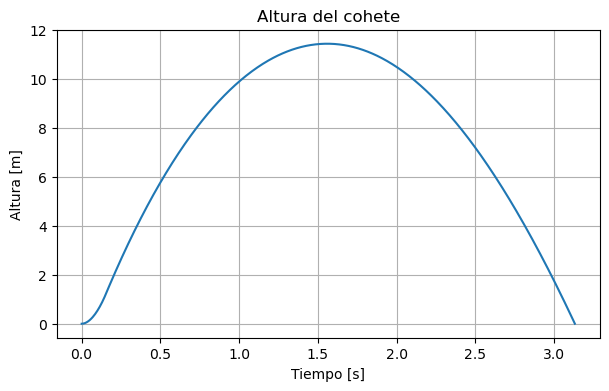

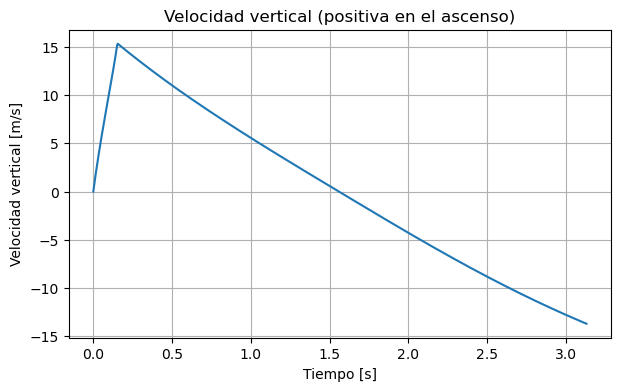

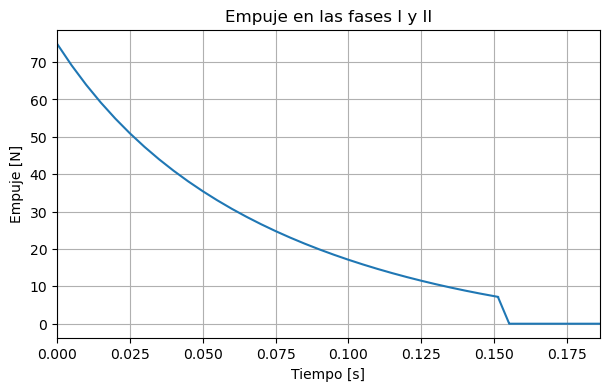

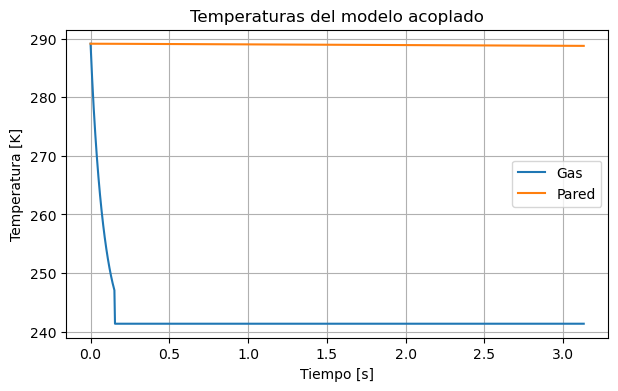

In [10]:
# Gráficas principales
plt.figure(figsize=(7,4))
plt.plot(resultados.t, resultados.y)
plt.xlabel('Tiempo [s]')
plt.ylabel('Altura [m]')
plt.title('Altura del cohete')
plt.grid()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(resultados.t, resultados.vy)
plt.xlabel('Tiempo [s]')
plt.ylabel('Velocidad vertical [m/s]')
plt.title('Velocidad vertical (positiva en el ascenso)')
plt.grid()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(resultados.t, resultados.F)
plt.xlabel('Tiempo [s]')
plt.ylabel('Empuje [N]')
plt.title('Empuje en las fases I y II')
plt.xlim(0, min(tb*1.2, resultados.t.max()))
plt.grid()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(resultados.t, resultados.Tg, label='Gas')
plt.plot(resultados.t, resultados.Tw, label='Pared')
plt.xlabel('Tiempo [s]')
plt.ylabel('Temperatura [K]')
plt.title('Temperaturas del modelo acoplado')
plt.legend()
plt.grid()
plt.show()

## 5. Convergencia numérica

In [12]:
tabla_convergencia = []
for paso in [0.004, 0.002, 0.001]:
    datos, _, _, _, _ = simular(paso_maximo=paso, tolerancia=1e-8)
    tabla_convergencia.append([paso, datos.y.max(), datos.x.iloc[-1], datos.Vrel.max()])

conv = pd.DataFrame(tabla_convergencia,
                    columns=['Paso máximo [s]', 'Altura máx [m]', 'Alcance [m]', 'Velocidad máx [m/s]'])
display(conv)
print('Diferencia entre los dos últimos apogeos:',
      abs(conv['Altura máx [m]'].iloc[-1]-conv['Altura máx [m]'].iloc[-2]), 'm')

,Paso máximo [s],Altura máx [m],Alcance [m],Velocidad máx [m/s]
0,0.004,11.432476,2.689642e-15,15.348622
1,0.002,11.432487,2.689644e-15,15.348631
2,0.001,11.432485,2.689644e-15,15.348630


Diferencia entre los dos últimos apogeos: 1.3269385465974892e-06 m


## 6. T3.2 — Convección interna

Comparación de $h_i=0$, $4{,}9$ y $5000$ W/(m²·K). Curvas propulsivas con lanzamiento vertical; alcance horizontal evaluado separadamente a 45°.


,hi [W/(m2 K)],Apogeo [m],Tg mínima [K],F máxima [N],Impulso [N s],Vuelo [s],Alcance a 45° [m]
0,0.0,11.279,240.453,74.916,4.478,3.110,21.135
1,4.9,11.432,241.348,74.916,4.494,3.131,21.394
2,5000.0,17.960,280.850,74.916,5.230,3.905,31.889


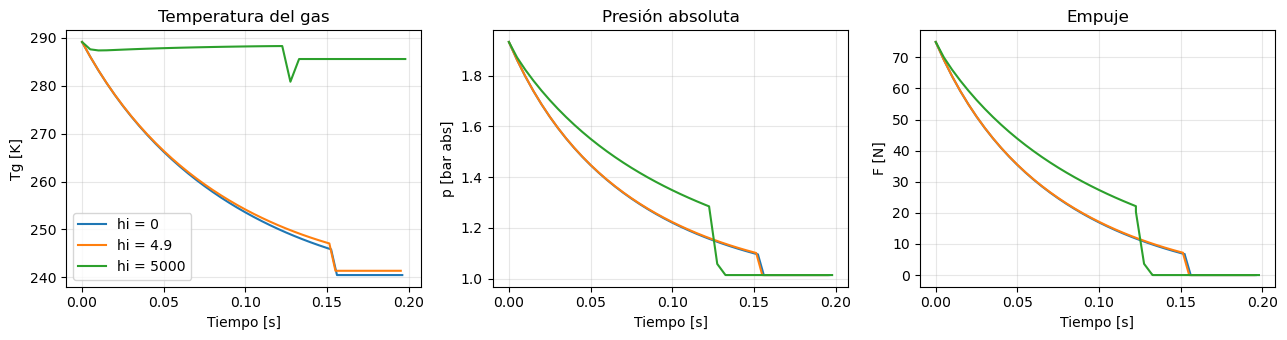

In [13]:
hi_base, theta_base = hi, theta0
casos_32 = {}
filas_32 = []
try:
    for hi_caso in [0.0, 4.9, 5000.0]:
        hi = hi_caso
        theta0 = 90.0
        vertical, _, ta_c, tb_c, _ = simular()
        theta0 = 45.0
        inclinado, _, _, _, _ = simular()
        casos_32[hi_caso] = (vertical, tb_c)
        impulso_c = sum(trapezoid(f.F, f.t) for f in
                        [vertical[vertical.fase == 1], vertical[vertical.fase == 2]])
        filas_32.append([hi_caso, vertical.y.max(), vertical.Tg.min(),
                         vertical.F.max(), impulso_c, vertical.t.iloc[-1], inclinado.x.iloc[-1]])
finally:
    hi, theta0 = hi_base, theta_base

tabla_32 = pd.DataFrame(filas_32, columns=['hi [W/(m2 K)]', 'Apogeo [m]',
    'Tg mínima [K]', 'F máxima [N]', 'Impulso [N s]', 'Vuelo [s]', 'Alcance a 45° [m]'])
display(tabla_32.round(3))

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
for valor, (datos, tb_c) in casos_32.items():
    prop = datos[datos.t <= 0.20]
    ejes[0].plot(prop.t, prop.Tg, label=f'hi = {valor:g}')
    ejes[1].plot(prop.t, prop.p/1e5)
    ejes[2].plot(prop.t, prop.F)
for eje, titulo, unidad in zip(ejes, ['Temperatura del gas', 'Presión absoluta', 'Empuje'],
                               ['Tg [K]', 'p [bar abs]', 'F [N]']):
    eje.set(xlabel='Tiempo [s]', ylabel=unidad, title=titulo)
    eje.grid(alpha=0.3)
ejes[0].legend()
plt.tight_layout(); plt.show()

# El intercambio intenso mantiene Tg y p más altas, eleva el impulso y acorta la descarga.
# F máxima es igual: al instante inicial aún no existe diferencia Tg–pared.
# A 90° el alcance horizontal es cero, por eso R se compara a 45°.


## 7. Conducción 1D del PET

Conducción transitoria del PET durante el vuelo, comparada con temperatura uniforme. La espuma añadida se evalúa por separado mediante un modelo equivalente en T3.1


Gradiente máximo entre superficies del PET: 0.08253 K


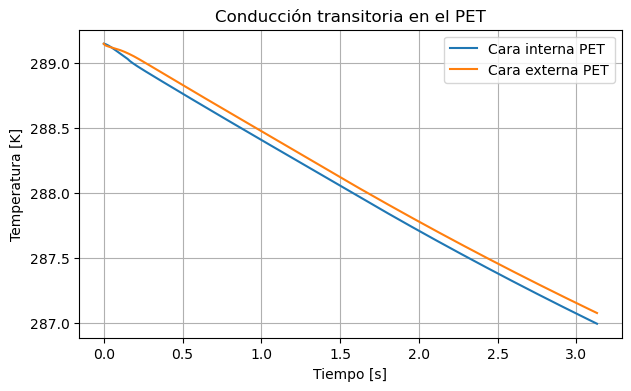

In [14]:
resolver_pared_1D = True

if resolver_pared_1D:
    if rhoPET is None or cpPET is None:
        raise ValueError('Ingresar rhoPET y cpPET en los datos de entrada.')

    N = 15                       # puntos de mediciones de calculo, elegidos arbitrariamente
    dx = ePET/(N-1)
    alfaPET = kPET/(rhoPET*cpPET)
    t_unicos = resultados.drop_duplicates('t', keep='last').sort_values('t')
    tiempos = t_unicos.t.to_numpy()
    temperatura_gas = t_unicos.Tg.to_numpy()
    h_exterior = t_unicos.hext.to_numpy()

    def ecuacion_pared(t, T):
        Tg_t = np.interp(t, tiempos, temperatura_gas)
        hext_t = np.interp(t, tiempos, h_exterior)
        dT = np.zeros(N)
        dT[1:-1] = alfaPET*(T[:-2]-2*T[1:-1]+T[2:])/dx**2

        q_interno = hi*(Tg_t-T[0])
        q_externo = (hext_t*(Tinf-T[-1])
                     + epsilon*sigma*(Tcielo**4-T[-1]**4)
                     + alpha_s*G*Ap/Alat)
        dT[0] = 2*(alfaPET*(T[1]-T[0])/dx**2
                   + q_interno/(rhoPET*cpPET*dx))
        dT[-1] = 2*(alfaPET*(T[-2]-T[-1])/dx**2
                    + q_externo/(rhoPET*cpPET*dx))
        return dT

    sol_pared = solve_ivp(ecuacion_pared,
                          [tiempos[0], tiempos[-1]], np.full(N, Tw0),
                          method='BDF', t_eval=tiempos, rtol=1e-7, atol=1e-9)
    if not sol_pared.success:
        raise RuntimeError(sol_pared.message)
    delta_pared = np.abs(sol_pared.y[0]-sol_pared.y[-1])
    print('Gradiente máximo entre superficies del PET:',
          round(delta_pared.max(), 5), 'K')
    plt.figure(figsize=(7,4))
    plt.plot(sol_pared.t, sol_pared.y[0], label='Cara interna PET')
    plt.plot(sol_pared.t, sol_pared.y[-1], label='Cara externa PET')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Temperatura [K]')
    plt.title('Conducción transitoria en el PET')
    plt.legend()
    plt.grid()
    plt.show()


## 7.1 T3.1 — Biot y error térmico

Biot del PET desnudo y con 1 mm de espuma PUR. Se distingue el máximo simulado de $h_{ext}$ de la referencia de 145 W/(m²·K). El ensayo a 330 K es ilustrativo.


Vuelo: h externo máximo = 22.83 W/(m2 K)
Bi vuelo: PET = 0.0190; PET + espuma (1 mm) = 0.5897
Bi referencia (h=145): PET = 0.1208; PET + espuma = 3.7458
Error PET uniforme vs 1D en vuelo: 0.0236 K
Error ensayo PET: 0.2139 K; bicapa equivalente: 7.7274 K


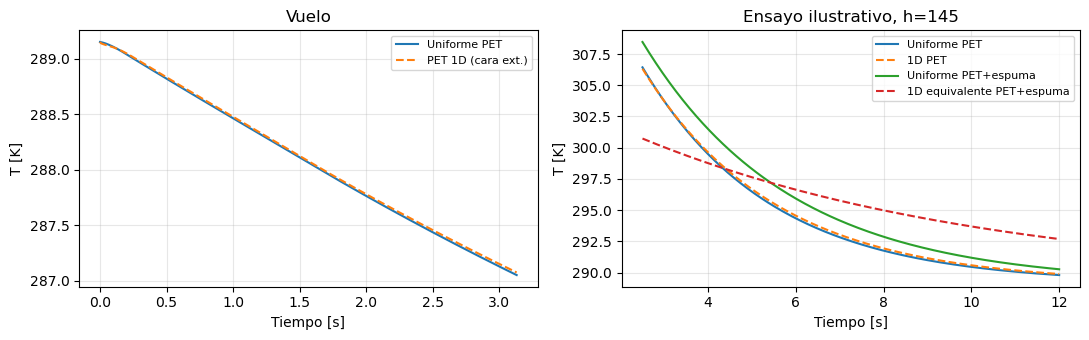

In [15]:
from scipy.optimize import brentq

L_esp = 0.001  # capa ilustrativa de espuma PUR [m]
h_vuelo = resultados.hext.max()
Bi_pet = h_vuelo * ePET/kPET
Bi_rec = h_vuelo * (ePET/kPET + L_esp/k_ais)
Bi_lab = h_ensayo * ePET/kPET
Bi_lab_rec = h_ensayo * (ePET/kPET + L_esp/k_ais)

# Error durante el vuelo: PET con temperatura uniforme frente a PET 1D.
t_1d = sol_pared.t
def pared_uniforme(t, T):
    hg = np.interp(t, tiempos, temperatura_gas)
    he = np.interp(t, tiempos, h_exterior)
    return [(hi*(hg-T[0]) + he*(Tinf-T[0])
             + epsilon*sigma*(Tcielo**4-T[0]**4))/(rhoPET*cpPET*ePET)]

agrupado = solve_ivp(pared_uniforme, [t_1d[0], t_1d[-1]], [Tw0],
                     t_eval=t_1d, method='BDF', rtol=1e-7, atol=1e-9).y[0]
err_vuelo = np.max(np.abs(agrupado - sol_pared.y[-1]))

# Ensayo ilustrativo: serie 1D de pared plana, cara opuesta aislada, Fo >= 0,2.
T_lab0 = 330.0
alfa_pet = kPET/(rhoPET*cpPET)
e_total = ePET + L_esp
k_equiv = e_total/(ePET/kPET + L_esp/k_ais)
cap_eq = rhoPET*cpPET*ePET + rho_ais*cp_ais*L_esp
alpha_equiv = k_equiv/(cap_eq/e_total)
t_inicio = max(0.2*ePET**2/alfa_pet, 0.2*e_total**2/alpha_equiv)
t_lab = np.linspace(t_inicio, 12, 250)
def curvas_serie(Bi, e, alfa, capacidad_areal):
    z = brentq(lambda w: w*np.tan(w)-Bi, 1e-9, np.pi/2-1e-9)
    C = 4*np.sin(z)/(2*z+np.sin(2*z))
    f = z*z*alfa*t_lab/e**2
    uno_d = Tinf+(T_lab0-Tinf)*C*np.cos(z)*np.exp(-f)
    unif = Tinf+(T_lab0-Tinf)*np.exp(-h_ensayo*t_lab/capacidad_areal)
    return uno_d, unif

T_pet_1d, T_pet_uniforme = curvas_serie(Bi_lab, ePET, alfa_pet, rhoPET*cpPET*ePET)
err_lab = np.max(np.abs(T_pet_uniforme-T_pet_1d))

# Bicapa PET/PUR: aproximación homogénea equivalente, Fo >= 0,2.
T_esp_1d, T_esp_uniforme = curvas_serie(Bi_lab_rec, e_total, alpha_equiv, cap_eq)
err_lab_rec = np.max(np.abs(T_esp_uniforme-T_esp_1d))

print(f'Vuelo: h externo máximo = {h_vuelo:.2f} W/(m2 K)')
print(f'Bi vuelo: PET = {Bi_pet:.4f}; PET + espuma (1 mm) = {Bi_rec:.4f}')
print(f'Bi referencia (h=145): PET = {Bi_lab:.4f}; PET + espuma = {Bi_lab_rec:.4f}')
print(f'Error PET uniforme vs 1D en vuelo: {err_vuelo:.4f} K')
print(f'Error ensayo PET: {err_lab:.4f} K; bicapa equivalente: {err_lab_rec:.4f} K')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t_1d, agrupado, label='Uniforme PET')
ax[0].plot(t_1d, sol_pared.y[-1], '--', label='PET 1D (cara ext.)')
ax[0].set(xlabel='Tiempo [s]', ylabel='T [K]', title='Vuelo')
ax[1].plot(t_lab, T_pet_uniforme, label='Uniforme PET')
ax[1].plot(t_lab, T_pet_1d, '--', label='1D PET')
ax[1].plot(t_lab, T_esp_uniforme, label='Uniforme PET+espuma')
ax[1].plot(t_lab, T_esp_1d, '--', label='1D equivalente PET+espuma')
ax[1].set(xlabel='Tiempo [s]', ylabel='T [K]', title='Ensayo ilustrativo, h=145')
for eje in ax:
    eje.legend(fontsize=8)
    eje.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 7.2 T3.5 — Espuma PUR: espesor vs alcance

Barrido de 0–2 mm de espuma rígida de poliuretano: $k=0{,}040$ W/(m·K), $\rho=50$ kg/m³ y $c_p=1250$ J/(kg·K). Para evaluar alcance horizontal se usa lanzamiento a 45°; el caso base permanece vertical.


,Espuma [mm],Masa añadida [g],R térmica [K/W],Tau [s],Alcance [m],Apogeo [m],Pérdida alcance [%],Aumento R térmica [%]
0,0.0,0.00,0.640255,43.22,21.394,5.646,0.00,0.0000
1,0.5,2.65,0.758148,53.69,21.082,5.520,1.46,18.4134
2,1.0,5.30,0.876040,64.94,20.763,5.397,2.95,36.8267
3,1.5,7.95,0.993933,76.97,20.441,5.278,4.46,55.2401
4,2.0,10.60,1.111825,89.78,20.116,5.162,5.98,73.6535


Máximo alcance: 0.0 mm; R = 21.39 m
Tau considera convección y conducción, sin radiación.
La espuma aumenta la resistencia térmica y añade masa, reduciendo el alcance.


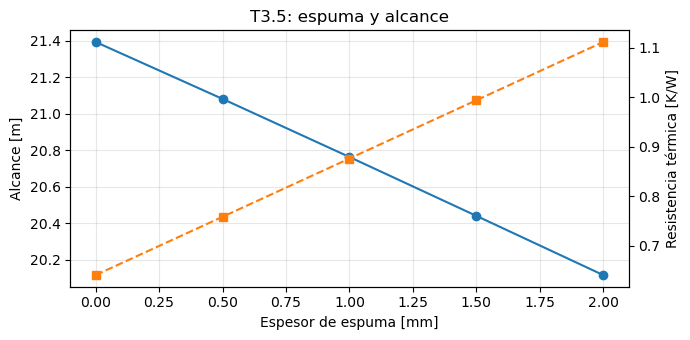

In [16]:
ms_base, m_rec_base, theta_base, e_base = ms, m_rec, theta0, e_ais
h_promedio = resultados.loc[resultados.hext > 0, 'hext'].mean()
filas_35 = []
try:
    theta0 = 45.0
    for esp in [0, 0.0005, 0.001, 0.0015, 0.002]:
        masa_extra = rho_ais*Alat*esp
        ms = ms_base + masa_extra
        m_rec = m_rec_base + masa_extra
        e_ais = esp
        vuelo, _, _, _, _ = simular(paso_maximo=0.004)
        R_term = (1/h_promedio + ePET/kPET + esp/k_ais)/Alat
        C_term = m_est*c_est + m_rec*c_rec
        filas_35.append([esp*1000, masa_extra*1000, R_term,
                         C_term*R_term, vuelo.x.iloc[-1], vuelo.y.max()])
finally:
    ms, m_rec, theta0, e_ais = ms_base, m_rec_base, theta_base, e_base

tabla_35 = pd.DataFrame(filas_35, columns=['Espuma [mm]', 'Masa añadida [g]',
    'R térmica [K/W]', 'Tau [s]', 'Alcance [m]', 'Apogeo [m]'])
tabla_35['Pérdida alcance [%]'] = 100*(1-tabla_35['Alcance [m]']/tabla_35['Alcance [m]'].iloc[0])
tabla_35['Aumento R térmica [%]'] = 100*(tabla_35['R térmica [K/W]']/tabla_35['R térmica [K/W]'].iloc[0]-1)
display(tabla_35.round({'Espuma [mm]':1, 'Masa añadida [g]':2,
                        'R térmica [K/W]':6, 'Tau [s]':2, 'Alcance [m]':3,
                        'Apogeo [m]':3, 'Pérdida alcance [%]':2,
                        'Aumento R térmica [%]':4}))
mejor_35 = tabla_35.loc[tabla_35['Alcance [m]'].idxmax()]
print(f'Máximo alcance: {mejor_35["Espuma [mm]"]:.1f} mm; '
      f'R = {mejor_35["Alcance [m]"]:.2f} m')
print('Tau considera convección y conducción, sin radiación.')
print('La espuma aumenta la resistencia térmica y añade masa, reduciendo el alcance.')

fig, a = plt.subplots(figsize=(7, 3.5))
a.plot(tabla_35['Espuma [mm]'], tabla_35['Alcance [m]'], 'o-')
a.set(xlabel='Espesor de espuma [mm]', ylabel='Alcance [m]')
b = a.twinx()
b.plot(tabla_35['Espuma [mm]'], tabla_35['R térmica [K/W]'], 's--', color='tab:orange')
b.set_ylabel('Resistencia térmica [K/W]')
a.grid(alpha=0.3)
plt.title('T3.5: espuma y alcance')
plt.tight_layout(); plt.show()


## 8. T3.4 — Mapa térmico y tablas para el informe

Modelo base con emisividad exterior estimada $\varepsilon=0{,}90$. Las tablas se recalculan a partir de la simulación actual.


In [17]:
# Simulación base, sin espuma adicional.
res34, partes34, ta34, tb34, agua34 = simular()
print('Tiempo expulsión de agua:', round(ta34, 5), 's')
print('Tiempo fin del empuje:  ', round(tb34, 5), 's')
print('Altura máxima:          ', round(res34.y.max(), 3), 'm')
print('Duración del vuelo:     ', round(res34.t.iloc[-1], 3), 's')


Tiempo expulsión de agua: 0.15141 s
Tiempo fin del empuje:   0.15514 s
Altura máxima:           11.432 m
Duración del vuelo:      3.131 s


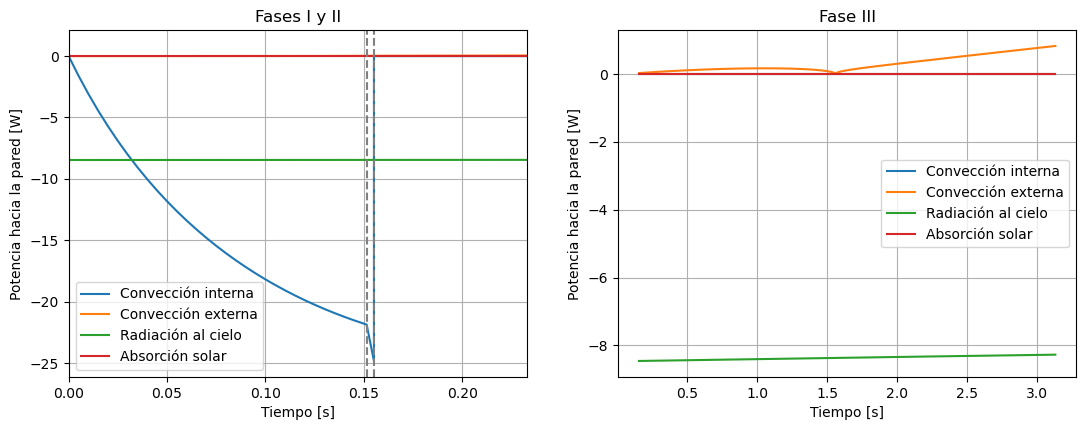

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].plot(res34.t, -res34.Qi, label='Convección interna')
ejes[0].plot(res34.t, res34.Qext, label='Convección externa')
ejes[0].plot(res34.t, res34.Qrad, label='Radiación al cielo')
ejes[0].plot(res34.t, res34.Qsolar, label='Absorción solar')
ejes[0].axvline(ta34, color='gray', linestyle='--')
ejes[0].axvline(tb34, color='gray', linestyle='--')
ejes[0].set_xlim(0, tb34*1.5)
ejes[0].set_xlabel('Tiempo [s]')
ejes[0].set_ylabel('Potencia hacia la pared [W]')
ejes[0].set_title('Fases I y II')
ejes[0].legend()
ejes[0].grid()

fase3 = res34[res34.fase == 3]
ejes[1].plot(fase3.t, -fase3.Qi, label='Convección interna')
ejes[1].plot(fase3.t, fase3.Qext, label='Convección externa')
ejes[1].plot(fase3.t, fase3.Qrad, label='Radiación al cielo')
ejes[1].plot(fase3.t, fase3.Qsolar, label='Absorción solar')
ejes[1].set_xlabel('Tiempo [s]')
ejes[1].set_ylabel('Potencia hacia la pared [W]')
ejes[1].set_title('Fase III')
ejes[1].legend()
ejes[1].grid()

plt.show()

Potencias térmicas medias [W]


,Duración [s],Conv. interna,Conv. externa,Radiación,Solar
Fase I,0.1514,14.0849,0.0040,-8.4615,0.0
Fase II,0.0037,23.3467,0.0239,-8.4573,0.0
Fase III,2.9761,0.0000,0.2995,-8.3622,0.0


Energía acumulada [J]


,Conv. interna,Conv. externa,Radiación,Solar,Total
Fase I,2.1326,0.0006,1.2812,0.0,3.4144
Fase II,0.0869,0.0001,0.0315,0.0,0.1185
Fase III,0.0000,0.8913,24.8868,0.0,25.7781
Total,2.2196,0.8920,26.1995,0.0,29.3110


Participación [%]


,Conv. interna,Conv. externa,Radiación,Solar
Fase I,62.46,0.02,37.52,0.0
Fase II,73.35,0.07,26.57,0.0
Fase III,0.00,3.46,96.54,0.0
Total,7.57,3.04,89.38,0.0


Total del vuelo: 29.311 J


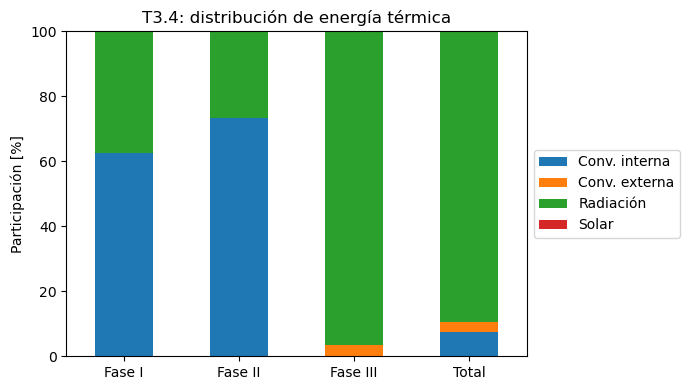

In [19]:
mecanismos = ['Qi', 'Qext', 'Qrad', 'Qsolar']
nombres_mec = ['Conv. interna', 'Conv. externa', 'Radiación', 'Solar']
fases = {1: 'Fase I', 2: 'Fase II', 3: 'Fase III'}

def tablas_termicas(datos):
    q = pd.DataFrame(0.0, index=list(fases.values()), columns=nombres_mec)
    pot = q.copy()
    pot.insert(0, 'Duración [s]', 0.0)
    for f, nombre in fases.items():
        d = datos[datos.fase == f]
        dt = d.t.iloc[-1]-d.t.iloc[0]
        pot.loc[nombre, 'Duración [s]'] = dt
        for k, nombre_k in zip(mecanismos, nombres_mec):
            q.loc[nombre, nombre_k] = trapezoid(np.abs(d[k]), d.t)
            pot.loc[nombre, nombre_k] = trapezoid(d[k], d.t)/dt
    q.loc['Total'] = q.sum()
    q['Total'] = q[nombres_mec].sum(axis=1)
    pct = 100*q[nombres_mec].div(q.Total, axis=0)
    return pot, q, pct

potencia_media, energia_acumulada, participacion = tablas_termicas(res34)
print('Potencias térmicas medias [W]')
display(potencia_media.round(4))
print('Energía acumulada [J]')
display(energia_acumulada.round(4))
print('Participación [%]')
display(participacion.round(2))
print('Total del vuelo:', round(energia_acumulada.loc['Total', 'Total'], 4), 'J')

participacion.plot(kind='bar', stacked=True, figsize=(7, 4))
plt.ylabel('Participación [%]')
plt.title('T3.4: distribución de energía térmica')
plt.xticks(rotation=0)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()


## 9. T6.2 — Protección térmica semi-infinita

Flujo constante entrante $q''=1$ MW/m² a $x=0$, $-k\,\partial T/\partial x=q''$; inicialmente $T(x,0)=289{,}15$ K y al fondo $T(\infty,t)=289{,}15$ K. Se busca la profundidad cuya temperatura llega a 450 K a los 300 s. Es un espesor idealizado (sin radiación, ablación ni variación de propiedades) la temperatura superficial predicha puede ser físicamente inviable. Se adopta el siguiente milímetro completo para cumplir $T<450$ K.

In [20]:
from scipy.special import erfc
from scipy.optimize import brentq

q = 1.0e6              # flujo de calor en la superficie [W/m2]
k_aisl = 0.1           # conductividad del aislante [W/(m K)]
alfa_aisl = 2e-7       # difusividad del aislante [m2/s]
t_reent = 300.0        # duración del flujo [s]
T_limite = 450.0       # temperatura máxima de la estructura [K]
T_inicial = 289.15     # temperatura inicial del sólido [K]

In [21]:
def temperatura(x, t):
    u = x / (2*np.sqrt(alfa_aisl*t))
    termino1 = 2*q/k_aisl * np.sqrt(alfa_aisl*t/np.pi) * np.exp(-u**2)
    termino2 = q*x/k_aisl * erfc(u)
    return T_inicial + termino1 - termino2

espesor_crit = brentq(lambda x: temperatura(x, t_reent) - T_limite, 0.0, 0.5)
espesor = np.ceil(espesor_crit*1000)/1000  # al siguiente mm completo
T_superficie = temperatura(0.0, t_reent)
penetracion = 4*np.sqrt(alfa_aisl*t_reent)

print('Espesor mínimo teórico:   ', round(espesor_crit*1000, 2), 'mm')
print('Espesor adoptado:         ', round(espesor*1000, 2), 'mm')
print('Temperatura en ese espesor: ', round(temperatura(espesor, t_reent), 3), 'K')
print('Temperatura de la superficie:', round(T_superficie, 0), 'K')
print('Profundidad de penetración 4*sqrt(alfa*t):', round(penetracion*1000, 2), 'mm')

Espesor mínimo teórico:    30.79 mm
Espesor adoptado:          31.0 mm
Temperatura en ese espesor:  439.912 K
Temperatura de la superficie: 87693.0 K
Profundidad de penetración 4*sqrt(alfa*t): 30.98 mm


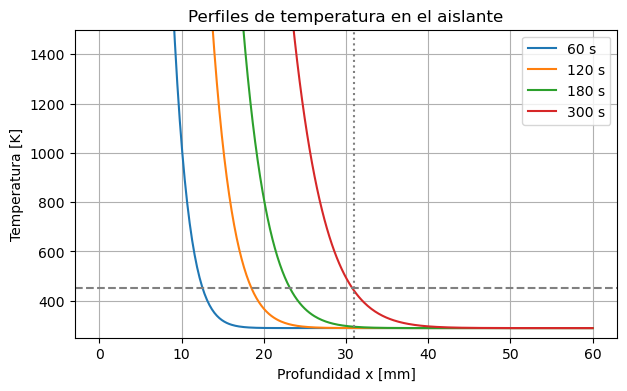

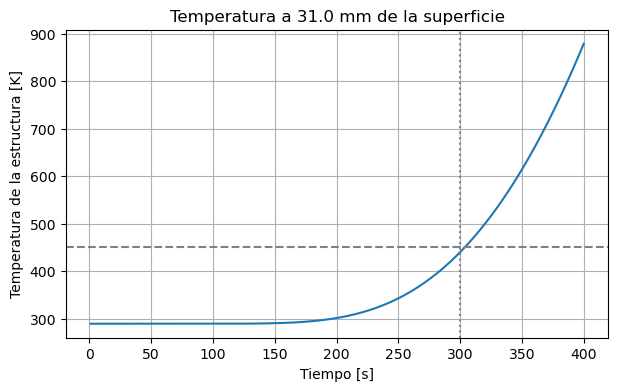

In [22]:
x = np.linspace(0, max(0.06, espesor*1.5), 400)
plt.figure(figsize=(7, 4))
for t in [60, 120, 180, 300]:
    plt.plot(x*1000, temperatura(x, t), label=str(t) + ' s')
plt.axhline(T_limite, color='gray', linestyle='--')
plt.axvline(espesor*1000, color='gray', linestyle=':')
plt.ylim(250, 1500)
plt.xlabel('Profundidad x [mm]')
plt.ylabel('Temperatura [K]')
plt.title('Perfiles de temperatura en el aislante')
plt.legend()
plt.grid()
plt.show()

tiempos = np.linspace(1, 400, 400)
plt.figure(figsize=(7, 4))
plt.plot(tiempos, temperatura(espesor, tiempos))
plt.axhline(T_limite, color='gray', linestyle='--')
plt.axvline(t_reent, color='gray', linestyle=':')
plt.xlabel('Tiempo [s]')
plt.ylabel('Temperatura de la estructura [K]')
plt.title('Temperatura a ' + str(round(espesor*1000, 1)) + ' mm de la superficie')
plt.grid()
plt.show()